 
### In this study we are going to perform Multi class Logistic Regression. We are going to use handwritten digit's dataset from Sklearn.



# Introduction

When outcome has more than two categories, Multi class regression is used for classification. For e.g. mail classification as primary, social, promotions, forums.

Say, a classification problem is to classify various fruits into three types of fruits: banana, orange or apple. Now, this is clearly a multi-class classification problem. If you want to use a binary classification algorithm like, say SVM. The way One-vs-Rest method will deal with this is illustrated below : 

Since there are three classes in the classification problem, the One-vs-Rest method will break down this problem into three binary classification problems:

Problem 1 : Banana vs [Orange, Apple]

Problem 2 : Orange vs [Banana, Apple]

Problem 3 : Apple vs [Banana, Orange]

So instead of solving it as (Banana vs Orange vs Apple), it is solved using three binary classification problems as shown above.


A major downside or disadvantage of this method is that many models have to be created. For a multi-class problem with ‘n’ number of classes, ‘n’ number of models have to be created, which may slow down the entire process. However, it is very useful with datasets having a small number of classes, where we want to use a model like SVM or Logistic Regression.

We are going to use One Vs Rest (OVR) algorithm.
 
This is also called as one vs all algorithm. As name suggest in this algorithm we choose one class and put all other classes into second virtual class and run the binary logistic regression on it. We repeat this procedure for all the classes in the dataset. So we actually end up with binary classifiers designed to recognize each class in dataset


<b>
   This approach requires that each model predicts a class membership probability or a probability-like score. The argmax of these scores (class index with the largest score) is then used to predict a class.
    
</b>
 
For prediction on given data, our algorithm returns probabilities for each class in the dataset and whichever class has the highest probability is our prediction

# Problem Statement
The data set contains images of hand-written digits: 10 classes where each class refers to a digit(0 to 9). Objective of our model is to predict the correct digit from 0 to 9, based on given handwritten image of digit.

# Import Libraries
* pandas: Used for data manipulation and analysis
* numpy : Numpy is the core library for scientific computing in Python. It is used for working with arrays and matrices.
* matplotlib : It's plotting library, and we are going to use it for data visualization
* datasets: Here we are going to use 'load_digits' dataset
* model_selection: Here we are going to use model_selection.train_test_split() for splitting the data
* linear_model: Here we are going to linear_model.LogisticRegression() for classification
* metrics: Here we are going use metrics.plot_confusion_matrix() and metrics.classification_report() for model analysis

In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
from sklearn import datasets
from sklearn import model_selection
from sklearn import linear_model
from sklearn import metrics

# Load The Data
* We are going to use [Optical recognition of handwritten digits dataset](https://scikit-learn.org/stable/datasets/index.html#optical-recognition-of-handwritten-digits-dataset)
* Dataset characteristics are,
  - Number of Attributes: 64
  - Attribute Information: 8x8 image of integer pixels in the range 0 to 16.
  - Missing Attribute Values: None
  - Creator: Alpaydin (alpaydin ‘@’ boun.edu.tr)
  - Date: July; 1998

In [2]:
digits_df = datasets.load_digits()
print('Digits dataset structure= ', dir(digits_df))
print('Data shape= ', digits_df.data.shape)
print("Image Shape",digits_df.images.shape)    
print("target Shape",digits_df.target.shape) 
print('Data conatins pixel representation of each image, \n', digits_df.data)

Digits dataset structure=  ['DESCR', 'data', 'feature_names', 'frame', 'images', 'target', 'target_names']
Data shape=  (1797, 64)
Image Shape (1797, 8, 8)
target Shape (1797,)
Data conatins pixel representation of each image, 
 [[ 0.  0.  5. ...  0.  0.  0.]
 [ 0.  0.  0. ... 10.  0.  0.]
 [ 0.  0.  0. ... 16.  9.  0.]
 ...
 [ 0.  0.  1. ...  6.  0.  0.]
 [ 0.  0.  2. ... 12.  0.  0.]
 [ 0.  0. 10. ... 12.  1.  0.]]



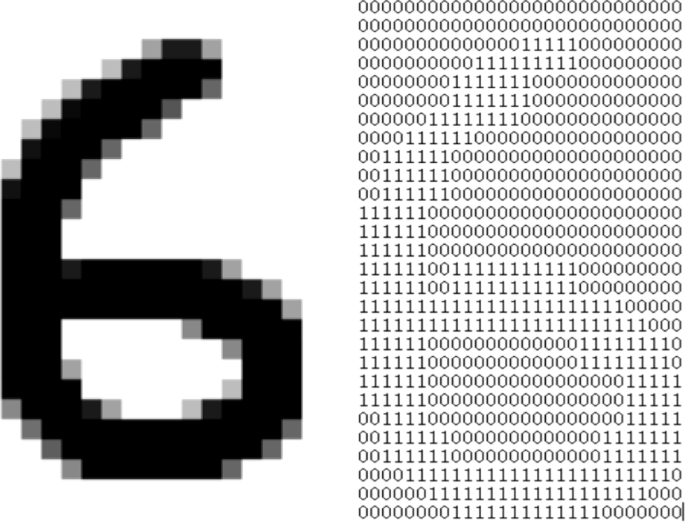

Overview of load_digits Dataset:
It is a built-in dataset in scikit-learn.

It contains images of handwritten digits from 0 to 9.

These digits are 8×8 grayscale images.


| Property         | Description                                                            |
|------------------|------------------------------------------------------------------------|
| `images`         | Array of shape (1797, 8, 8). Each digit is an 8×8 image.               |
| `data`           | Flattened version of images (1797, 64). Each image is 64 pixel values. |
| `target`         | The actual digit labels (0 to 9).                                      |
| `target_names`   | List of digit names (0 to 9).                                          |
| `DESCR`          | Description of the dataset.                                            |
| `feature_names`  | (Not applicable for image data; mostly used in tabular datasets.)      |


🔹 Use Case:
This dataset is great for:

Practicing classification algorithms.

Understanding image data in ML.

Working with logistic regression, SVM, k-NN, etc.


In [3]:
digits_df

{'data': array([[ 0.,  0.,  5., ...,  0.,  0.,  0.],
        [ 0.,  0.,  0., ..., 10.,  0.,  0.],
        [ 0.,  0.,  0., ..., 16.,  9.,  0.],
        ...,
        [ 0.,  0.,  1., ...,  6.,  0.,  0.],
        [ 0.,  0.,  2., ..., 12.,  0.,  0.],
        [ 0.,  0., 10., ..., 12.,  1.,  0.]]),
 'target': array([0, 1, 2, ..., 8, 9, 8]),
 'frame': None,
 'feature_names': ['pixel_0_0',
  'pixel_0_1',
  'pixel_0_2',
  'pixel_0_3',
  'pixel_0_4',
  'pixel_0_5',
  'pixel_0_6',
  'pixel_0_7',
  'pixel_1_0',
  'pixel_1_1',
  'pixel_1_2',
  'pixel_1_3',
  'pixel_1_4',
  'pixel_1_5',
  'pixel_1_6',
  'pixel_1_7',
  'pixel_2_0',
  'pixel_2_1',
  'pixel_2_2',
  'pixel_2_3',
  'pixel_2_4',
  'pixel_2_5',
  'pixel_2_6',
  'pixel_2_7',
  'pixel_3_0',
  'pixel_3_1',
  'pixel_3_2',
  'pixel_3_3',
  'pixel_3_4',
  'pixel_3_5',
  'pixel_3_6',
  'pixel_3_7',
  'pixel_4_0',
  'pixel_4_1',
  'pixel_4_2',
  'pixel_4_3',
  'pixel_4_4',
  'pixel_4_5',
  'pixel_4_6',
  'pixel_4_7',
  'pixel_5_0',
  'pixel_5_1',
 

In [4]:
digits_df.DESCR

".. _digits_dataset:\n\nOptical recognition of handwritten digits dataset\n--------------------------------------------------\n\n**Data Set Characteristics:**\n\n    :Number of Instances: 1797\n    :Number of Attributes: 64\n    :Attribute Information: 8x8 image of integer pixels in the range 0..16.\n    :Missing Attribute Values: None\n    :Creator: E. Alpaydin (alpaydin '@' boun.edu.tr)\n    :Date: July; 1998\n\nThis is a copy of the test set of the UCI ML hand-written digits datasets\nhttps://archive.ics.uci.edu/ml/datasets/Optical+Recognition+of+Handwritten+Digits\n\nThe data set contains images of hand-written digits: 10 classes where\neach class refers to a digit.\n\nPreprocessing programs made available by NIST were used to extract\nnormalized bitmaps of handwritten digits from a preprinted form. From a\ntotal of 43 people, 30 contributed to the training set and different 13\nto the test set. 32x32 bitmaps are divided into nonoverlapping blocks of\n4x4 and the number of on pixel

In [5]:
digits_df.data[:1]

array([[ 0.,  0.,  5., 13.,  9.,  1.,  0.,  0.,  0.,  0., 13., 15., 10.,
        15.,  5.,  0.,  0.,  3., 15.,  2.,  0., 11.,  8.,  0.,  0.,  4.,
        12.,  0.,  0.,  8.,  8.,  0.,  0.,  5.,  8.,  0.,  0.,  9.,  8.,
         0.,  0.,  4., 11.,  0.,  1., 12.,  7.,  0.,  0.,  2., 14.,  5.,
        10., 12.,  0.,  0.,  0.,  0.,  6., 13., 10.,  0.,  0.,  0.]])

In [ ]:
digits_df.target[:1]

array([0])

In [7]:
digits_df.images[:10]

array([[[ 0.,  0.,  5., 13.,  9.,  1.,  0.,  0.],
        [ 0.,  0., 13., 15., 10., 15.,  5.,  0.],
        [ 0.,  3., 15.,  2.,  0., 11.,  8.,  0.],
        [ 0.,  4., 12.,  0.,  0.,  8.,  8.,  0.],
        [ 0.,  5.,  8.,  0.,  0.,  9.,  8.,  0.],
        [ 0.,  4., 11.,  0.,  1., 12.,  7.,  0.],
        [ 0.,  2., 14.,  5., 10., 12.,  0.,  0.],
        [ 0.,  0.,  6., 13., 10.,  0.,  0.,  0.]],

       [[ 0.,  0.,  0., 12., 13.,  5.,  0.,  0.],
        [ 0.,  0.,  0., 11., 16.,  9.,  0.,  0.],
        [ 0.,  0.,  3., 15., 16.,  6.,  0.,  0.],
        [ 0.,  7., 15., 16., 16.,  2.,  0.,  0.],
        [ 0.,  0.,  1., 16., 16.,  3.,  0.,  0.],
        [ 0.,  0.,  1., 16., 16.,  6.,  0.,  0.],
        [ 0.,  0.,  1., 16., 16.,  6.,  0.,  0.],
        [ 0.,  0.,  0., 11., 16., 10.,  0.,  0.]],

       [[ 0.,  0.,  0.,  4., 15., 12.,  0.,  0.],
        [ 0.,  0.,  3., 16., 15., 14.,  0.,  0.],
        [ 0.,  0.,  8., 13.,  8., 16.,  0.,  0.],
        [ 0.,  0.,  1.,  6., 15., 11.,  0.,  0

# Data Understanding
Dataset contains 10 classes(0 to 9 digits). There are 180 training example per class and total 1797 training examples. Each training example is 8x8 image i.e. flat array of 64 pixels or matrix of 8x8. Each pixel value is represented by integer from 0 to 16. So our input data is of shape (1797x64) i.e. 1797 rows and 64 columns
 
* digits.DESCR: Description of the dataset
* digits.data:  
  - ndarray of shape (1797, 64)
  - The flattened data matrix of training data.i.e Every 8x8 image data matrix is converted to 64 pixel flat array. 
  - We are going to use this data for model training
* digits.images:  
  - ndarray of shape (1797, 8, 8)
  - It contains raw image data in the form of 8x8 matrix
  - We are going to use this data for plotting the images
* digits.target: Contains target value(0 to 9) for each training examples, so it contains 1797, y labels
* digits.target_names: Contains name for each target since we have 10 classes it contains 10 names only
 
Here digits.data is our independent/inputs/ X variables
 
And digits.target is our dependent/target/y variable

## Data Visualization
Let's visualize the images from digits dataset

In [10]:
digits_df

{'data': array([[ 0.,  0.,  5., ...,  0.,  0.,  0.],
        [ 0.,  0.,  0., ..., 10.,  0.,  0.],
        [ 0.,  0.,  0., ..., 16.,  9.,  0.],
        ...,
        [ 0.,  0.,  1., ...,  6.,  0.,  0.],
        [ 0.,  0.,  2., ..., 12.,  0.,  0.],
        [ 0.,  0., 10., ..., 12.,  1.,  0.]]),
 'target': array([0, 1, 2, ..., 8, 9, 8]),
 'frame': None,
 'feature_names': ['pixel_0_0',
  'pixel_0_1',
  'pixel_0_2',
  'pixel_0_3',
  'pixel_0_4',
  'pixel_0_5',
  'pixel_0_6',
  'pixel_0_7',
  'pixel_1_0',
  'pixel_1_1',
  'pixel_1_2',
  'pixel_1_3',
  'pixel_1_4',
  'pixel_1_5',
  'pixel_1_6',
  'pixel_1_7',
  'pixel_2_0',
  'pixel_2_1',
  'pixel_2_2',
  'pixel_2_3',
  'pixel_2_4',
  'pixel_2_5',
  'pixel_2_6',
  'pixel_2_7',
  'pixel_3_0',
  'pixel_3_1',
  'pixel_3_2',
  'pixel_3_3',
  'pixel_3_4',
  'pixel_3_5',
  'pixel_3_6',
  'pixel_3_7',
  'pixel_4_0',
  'pixel_4_1',
  'pixel_4_2',
  'pixel_4_3',
  'pixel_4_4',
  'pixel_4_5',
  'pixel_4_6',
  'pixel_4_7',
  'pixel_5_0',
  'pixel_5_1',
 

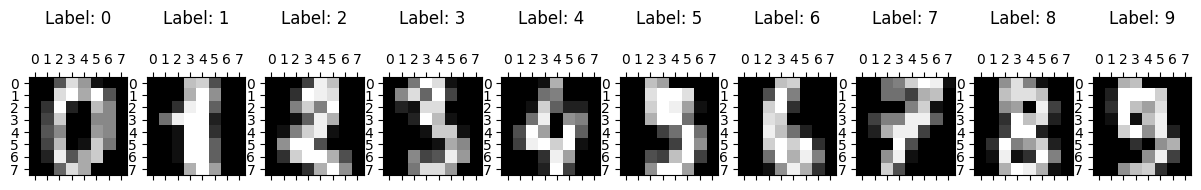

In [ ]:
# Using subplot to plot the digits from 0 to 9
rows = 1
columns = 10
fig, ax =  plt.subplots(rows, columns, figsize = (15,6))

plt.gray()
for i in range(columns):
  ax[i].matshow(digits_df.images[i]) 
  ax[i].set_title('Label: %s\n' % digits_df.target_names[i])

plt.show()

for start in range(0, 1797, 10): Loops through the dataset in steps of 10 (i.e., 0, 10, 20, ..., up to 1790).

fig, ax = plt.subplots(1, 10, ...): Creates a row of 10 subplots for each loop iteration.

img_index = start + i: Selects the actual image index from the dataset.

ax[i].matshow(...): Displays the image in grayscale.

ax[i].set_title(...): Shows the actual label from digits_df.target[...].

ax[i].axis('off'): Removes the axis to keep the view clean.

plt.show(): Displays each row of 10 images at a time.

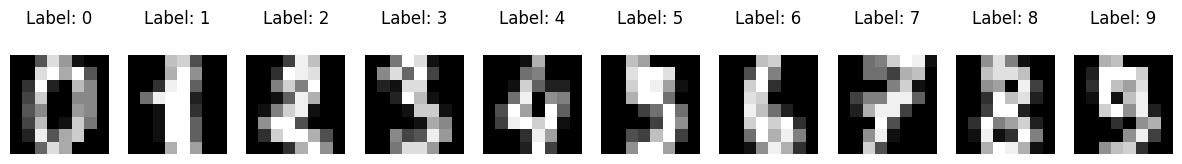

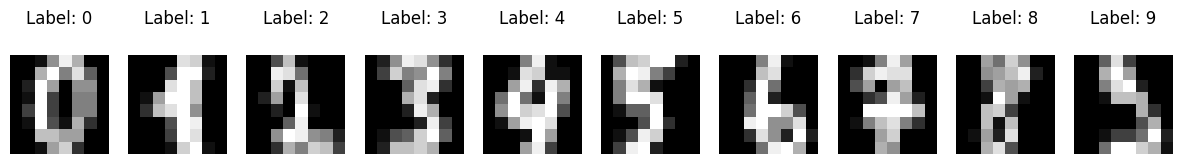

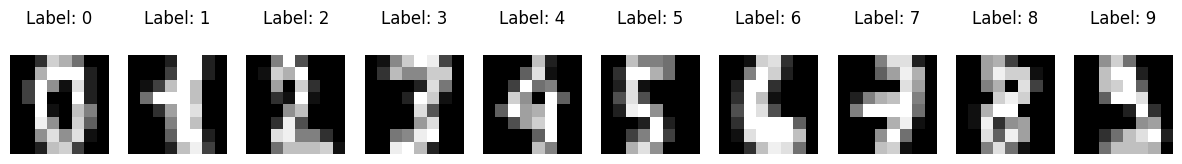

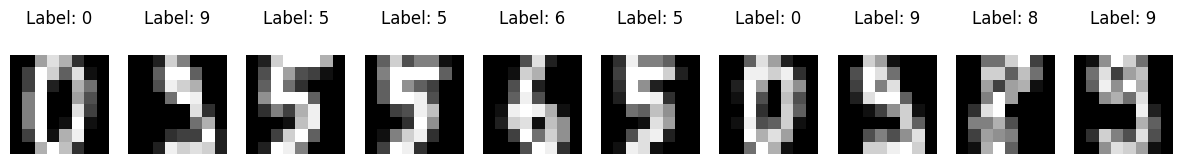

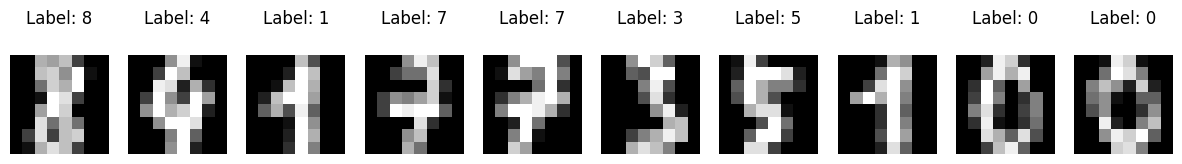

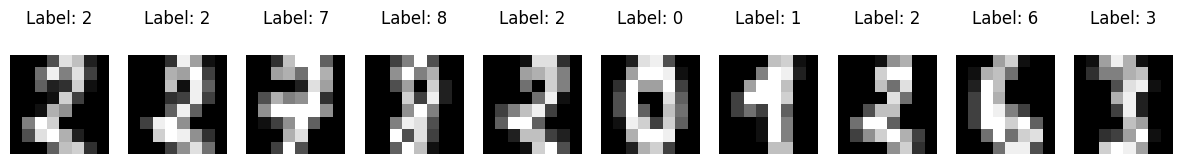

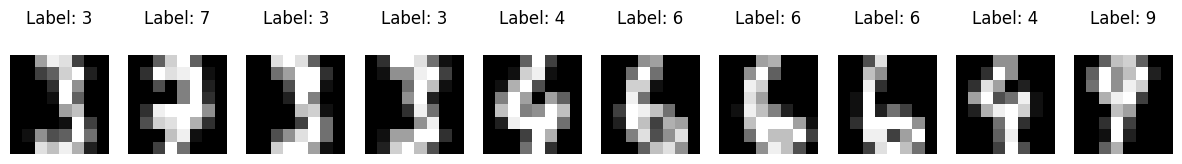

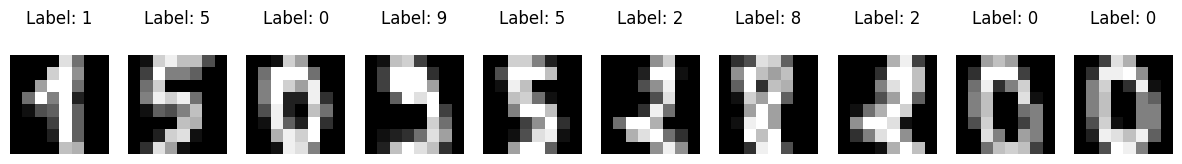

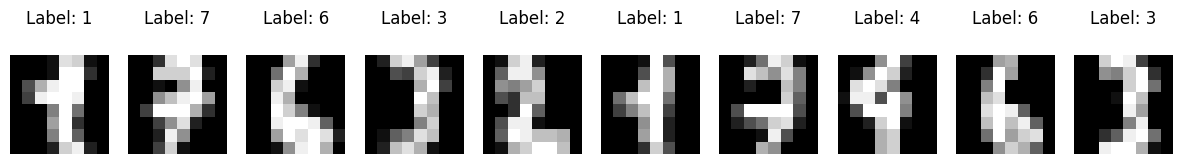

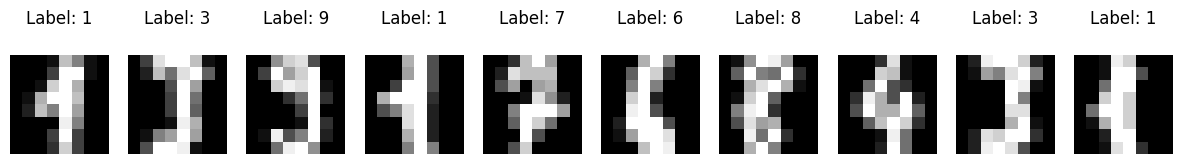

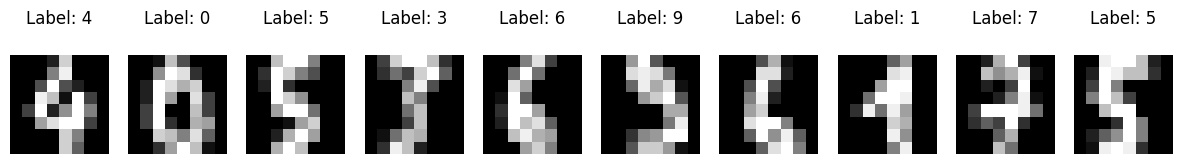

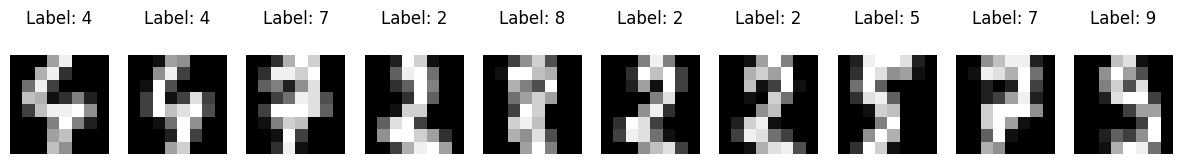

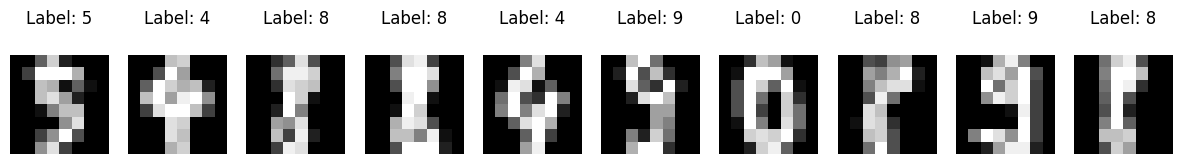

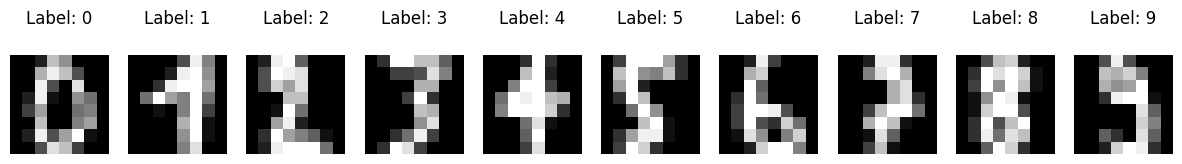

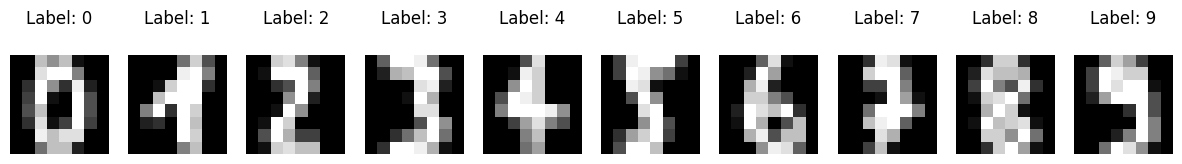

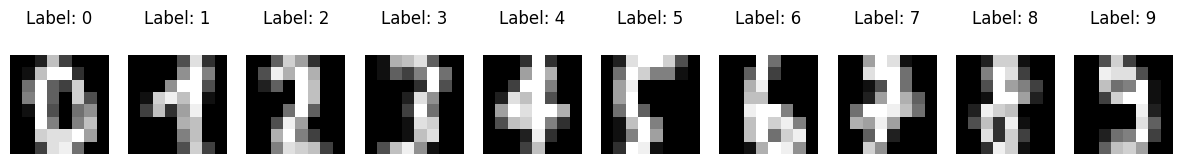

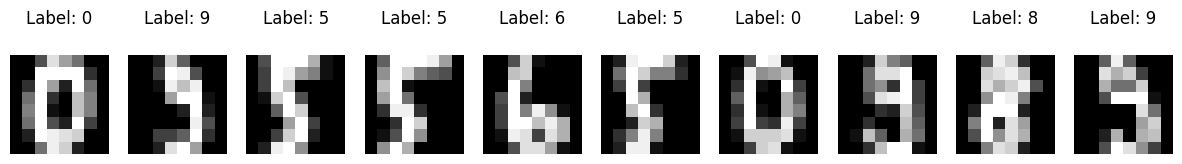

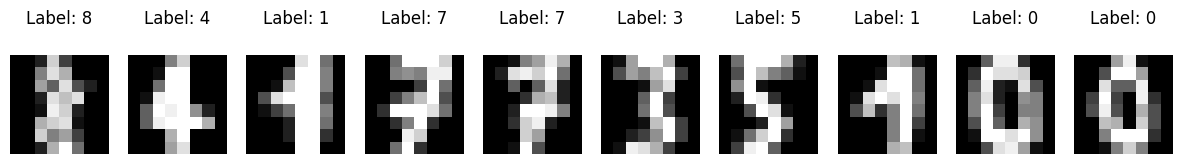

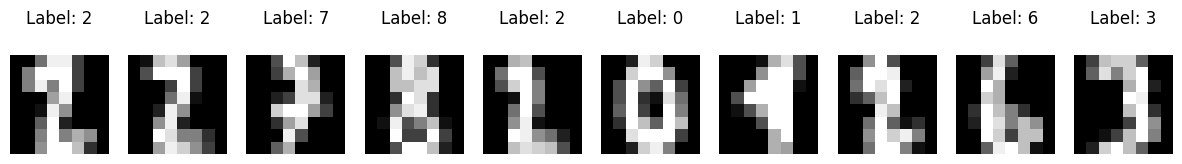

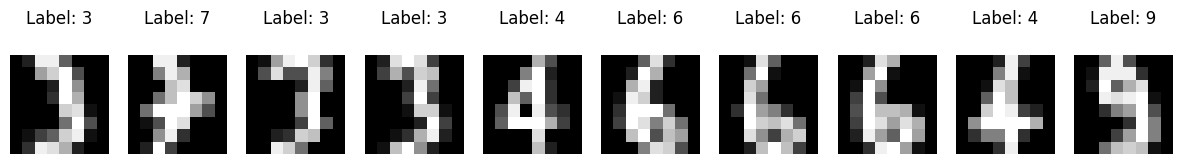

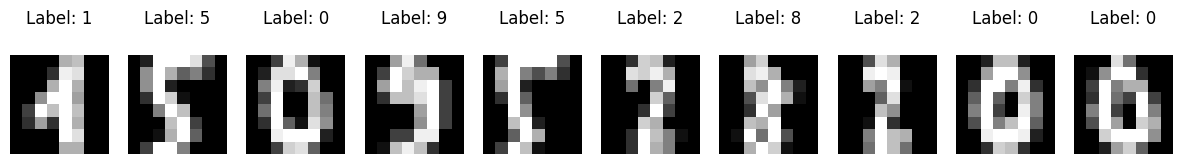

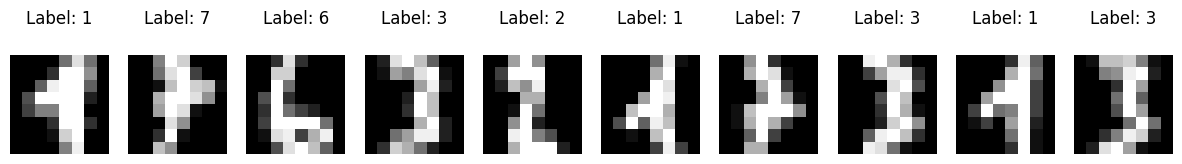

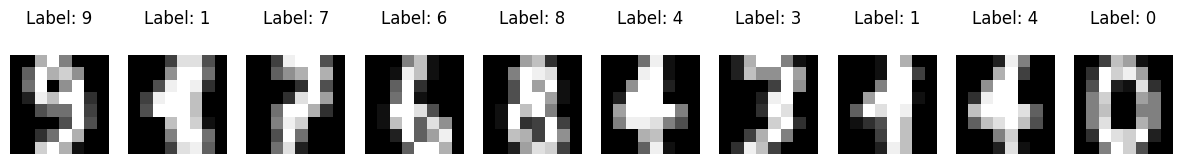

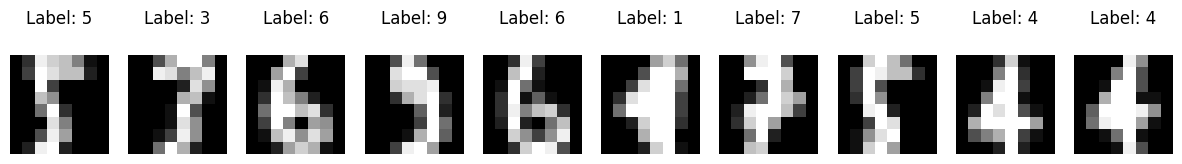

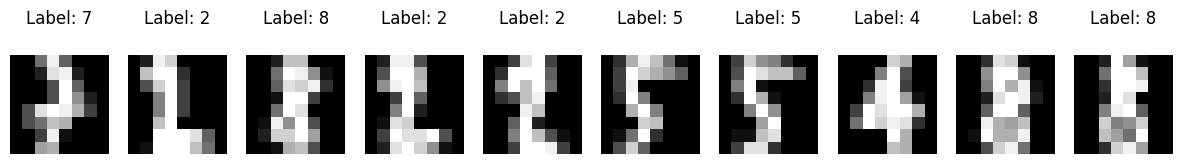

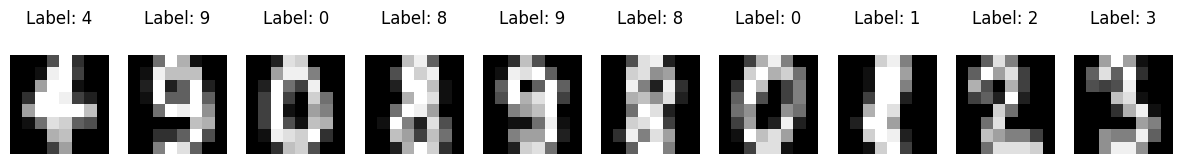

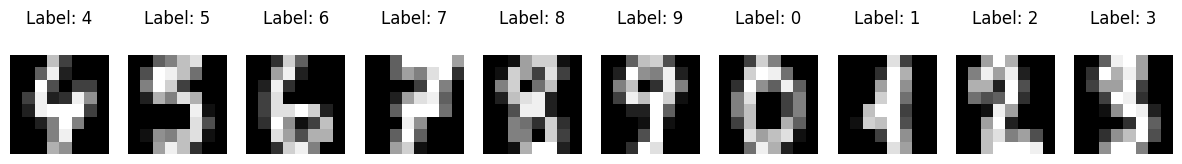

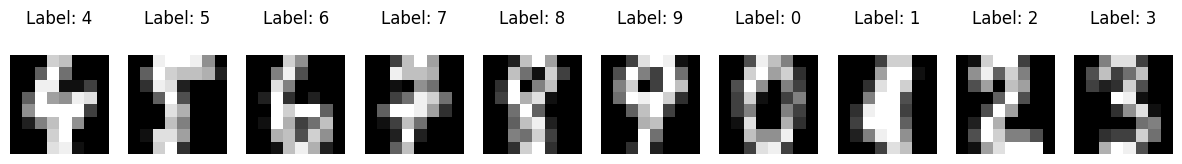

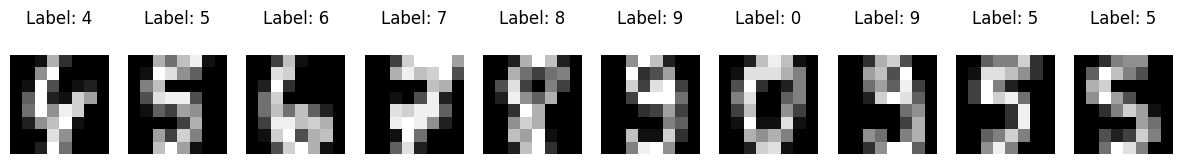

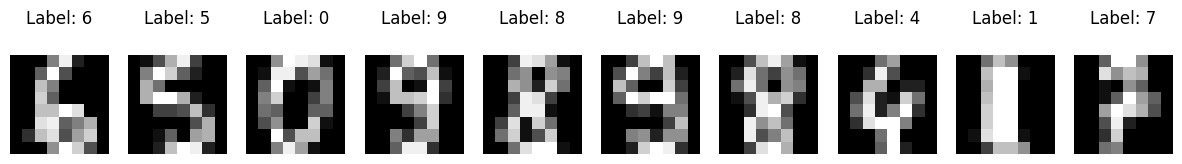

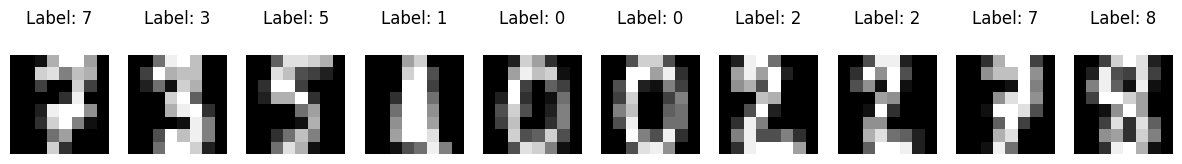

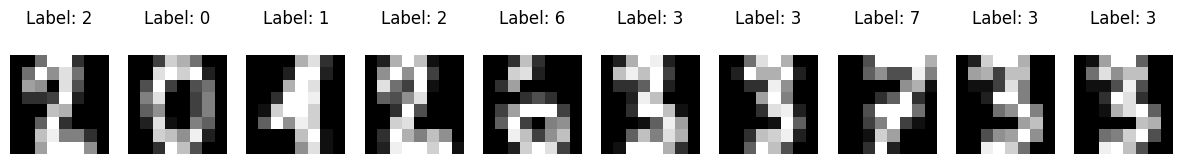

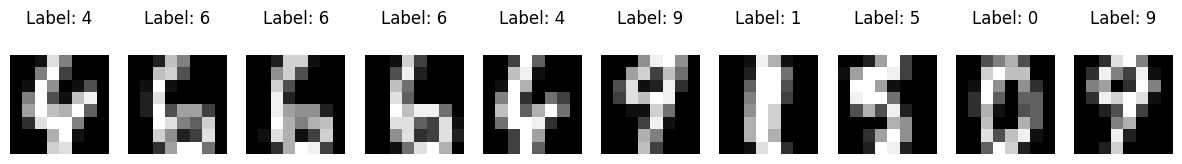

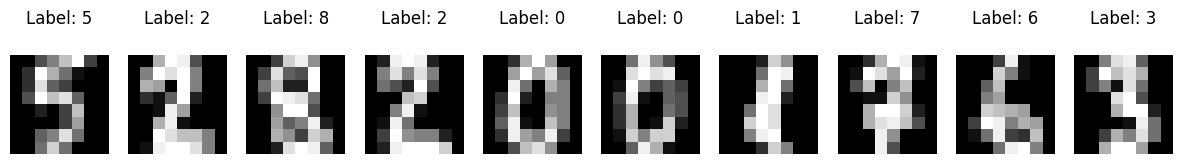

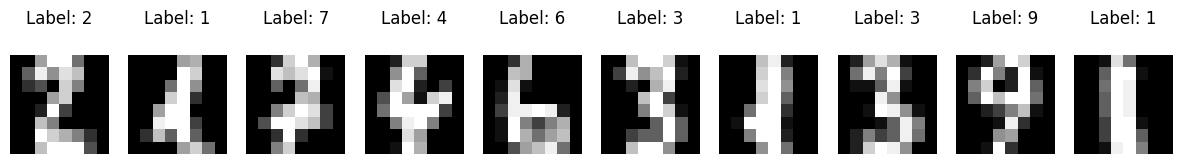

KeyboardInterrupt: 

In [27]:
for start in range(0, 1797, 10):
    fig, ax = plt.subplots(1, 10, figsize=(15, 4))
    for i in range(10):
        img_index = start + i
        if img_index < len(digits_df.images):
            ax[i].matshow(digits_df.images[img_index], cmap='gray')
            ax[i].set_title(f'Label: {digits_df.target[img_index]}')
            ax[i].axis('off')
    plt.show()

# Build Machine Learning Model

## Create Feature Matrix X and Label Vector y
Note for training and testing we are going to use 'digits_df.data' and not 'digits_df.images'

In [15]:
X = digits_df.data
y = digits_df.target

In [37]:
X[:1]

array([[ 0.,  0.,  5., 13.,  9.,  1.,  0.,  0.,  0.,  0., 13., 15., 10.,
        15.,  5.,  0.,  0.,  3., 15.,  2.,  0., 11.,  8.,  0.,  0.,  4.,
        12.,  0.,  0.,  8.,  8.,  0.,  0.,  5.,  8.,  0.,  0.,  9.,  8.,
         0.,  0.,  4., 11.,  0.,  1., 12.,  7.,  0.,  0.,  2., 14.,  5.,
        10., 12.,  0.,  0.,  0.,  0.,  6., 13., 10.,  0.,  0.,  0.]])

In [ ]:
y[:10]

array([0, 1, 2, 3, 4, 5, 6, 7, 8, 9])

## Create Test And Train Dataset
* We will split the dataset, so that we can use one set of data for training the model and one set of data for testing the model
* We will keep 20% of data for testing and 80% of data for training the model


In [31]:
X_train, X_test, y_train, y_test = model_selection.train_test_split(X, y, test_size= 0.2, random_state = 1)

print('X_train dimension= ', X_train.shape)
print('X_test dimension= ', X_test.shape)
print('y_train dimension= ', y_train.shape)
print('y_train dimension= ', y_test.shape)

X_train dimension=  (1437, 64)
X_test dimension=  (360, 64)
y_train dimension=  (1437,)
y_train dimension=  (360,)


Now lets train the model using OVR algorithm

## Multi class Logistic Regression Using OVR
* Since we are going to use One Vs Rest algorithm, set >  multi_class='ovr'


In [32]:
lm = linear_model.LogisticRegression(multi_class='ovr')
lm.fit(X_train, y_train)

c:\Users\USER\AppData\Local\Programs\Python\Python311\Lib\site-packages\sklearn\linear_model\_logistic.py:458: ConvergenceWarning: lbfgs failed to converge (status=1):
STOP: TOTAL NO. of ITERATIONS REACHED LIMIT.

Increase the number of iterations (max_iter) or scale the data as shown in:
    https://scikit-learn.org/stable/modules/preprocessing.html
Please also refer to the documentation for alternative solver options:
    https://scikit-learn.org/stable/modules/linear_model.html#logistic-regression
  n_iter_i = _check_optimize_result(


LogisticRegression(multi_class='ovr')

# Testing The Model
* For testing we are going to use the test data only
* **Question: Predict the value of 120th index digits from test data**

In [33]:
X_test[120]

array([ 0.,  0.,  0., 10., 16.,  7.,  0.,  0.,  0.,  0.,  2., 15.,  4.,
       14.,  2.,  0.,  0.,  0.,  0., 13.,  8., 16.,  0.,  0.,  0.,  0.,
        0., 10., 16., 14.,  1.,  0.,  0.,  0.,  8., 16., 16.,  7.,  0.,
        0.,  0.,  1., 15.,  6.,  8., 12.,  0.,  0.,  0.,  1., 13.,  5.,
       12.,  9.,  0.,  0.,  0.,  0.,  1., 11., 15.,  6.,  0.,  0.])

In [ ]:
print('Predicted value is =', lm.predict([X_test[120]]))
print('Actual value from test data is {} '.format( (y_test[120])) )


Predicted value is = [8]
Actual value from test data is 8 


## Model Score
Check the model score using test data

In [22]:
lm.score(X_test, y_test)

0.9666666666666667

## Confusion Matrix
* Confusion matrix helps to visualize the performance of the model
* The diagonal elements represent the number of points for which the predicted label is equal to the true label
* Off-diagonal elements are those that are mislabeled by the classifier.
* The higher the diagonal values of the confusion matrix the better, indicating many correct
 
Let's create confusion matrix using sklearn library and test data

array([[42,  0,  0,  0,  1,  0,  0,  0,  0,  0],
       [ 0, 34,  0,  0,  0,  0,  0,  0,  1,  0],
       [ 0,  0, 35,  1,  0,  0,  0,  0,  0,  0],
       [ 0,  0,  0, 39,  0,  0,  0,  0,  1,  1],
       [ 0,  0,  0,  0, 38,  0,  0,  0,  0,  0],
       [ 0,  0,  0,  1,  0, 29,  0,  0,  0,  0],
       [ 0,  0,  0,  0,  0,  0, 37,  0,  0,  0],
       [ 0,  0,  0,  0,  0,  0,  0, 36,  0,  1],
       [ 0,  0,  0,  0,  0,  1,  0,  0, 27,  1],
       [ 0,  0,  0,  0,  0,  1,  0,  0,  1, 32]])

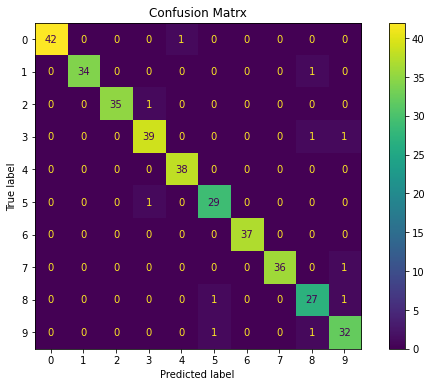

In [ ]:
#Creating matplotlib axes object to assign figuresize and figure title

fig, ax = plt.subplots(figsize=(10, 6))
ax.set_title('Confusion Matrx')

disp =metrics.plot_confusion_matrix(lm, X_test, y_test, display_labels= digits_df.target_names, ax = ax)
disp.confusion_matrix

This confusion matrix corresponds to a 10-class classification problem. 
Each row and column of the matrix corresponds to one of the classes (from 0 to 9).

### Reading the Matrix:
1.   Rows   represent the   actual   classes.
2.   Columns   represent the   predicted   classes.

#### Detailed Interpretation:

- Row 1, Column 1: There were 42 instances that were actually of class 0 and were correctly predicted as class 0.
- Row 1, Column 5: There was 1 instance that was actually of class 0 but was incorrectly predicted as class 4.
  
- Row 2, Column 2: There were 34 instances that were actually of class 1 and were correctly predicted as class 1.
- Row 2, Column 9: There was 1 instance that was actually of class 1 but was incorrectly predicted as class 8.
  
- Row 3, Column 3: There were 35 instances of class 2 that were correctly predicted.
- Row 3, Column 4: There was 1 instance that was actually of class 2 but was incorrectly predicted as class 3.
... and so on for each row.


### Key Observations:

1. The diagonal values (from top-left to bottom-right) represent correct predictions.
These are cases where the actual class matches the predicted class. 
Higher values in the diagonal elements are desirable as they indicate many correct predictions.

2. Off-diagonal values represent misclassifications. 
For instance, the value in Row 3, Column 4 represents the number of instances that were actually of class 2 but were predicted as class 3.

3. The sum of the values in a row represents the total number of 
instances of that actual class in the dataset. 
For example, the sum of all values in Row 1 represents the total number of instances of class 0.

4. By examining off-diagonal values, you can understand which classes 
are often confused with which other classes. For instance, if a certain off-diagonal cell has a high value, it indicates that those two classes are often misclassified with respect to each other.

From the given matrix, most of the values are on the diagonal, 
which indicates good classification performance. 
However, there are a few off-diagonal values, suggesting occasional misclassifications.

## deeper understanding

🔢 Row-by-row explanation:


Row 0 (Actual digit = 0):
✅ 42 images were correctly predicted as 0.

❌ 1 image was wrongly predicted as 4.

Row 1 (Actual digit = 1):
✅ 34 images were correctly predicted as 1.

❌ 1 image was wrongly predicted as 8.

Row 2 (Actual digit = 2):
✅ 35 images were correctly predicted as 2.

❌ 1 image was wrongly predicted as 3.

Row 3 (Actual digit = 3):
✅ 39 images were correctly predicted as 3.

❌ 1 image was wrongly predicted as 8.

❌ 1 image was wrongly predicted as 9.

Row 4 (Actual digit = 4):
✅ 38 images were correctly predicted as 4.

Row 5 (Actual digit = 5):
✅ 29 images were correctly predicted as 5.

❌ 1 image was wrongly predicted as 3.

Row 6 (Actual digit = 6):
✅ All 37 images were correctly predicted as 6.

Row 7 (Actual digit = 7):
✅ 36 images were correctly predicted as 7.

❌ 1 image was wrongly predicted as 9.

Row 8 (Actual digit = 8):
✅ 27 images were correctly predicted as 8.

❌ 1 image was wrongly predicted as 5.

❌ 1 image was wrongly predicted as 9.

Row 9 (Actual digit = 9):
✅ 32 images were correctly predicted as 9.

❌ 1 image was wrongly predicted as 5.

❌ 1 image was wrongly predicted as 8.

## Classification Report
Classification report is used to measure the quality of prediction from classification algorithm
 
* Precision: Indicates how many classes are correctly classified
* Recall: Indicates what proportions of actual positives was identified correctly
* F-Score: It is the harmonic mean between precision & recall
* Support: It is the number of occurrence of the given class in our dataset

In [10]:
print(metrics.classification_report(y_test, lm.predict(X_test)))

              precision    recall  f1-score   support

           0       1.00      0.98      0.99        43
           1       1.00      0.97      0.99        35
           2       1.00      0.97      0.99        36
           3       0.95      0.95      0.95        41
           4       0.97      1.00      0.99        38
           5       0.94      0.97      0.95        30
           6       1.00      1.00      1.00        37
           7       1.00      0.97      0.99        37
           8       0.90      0.93      0.92        29
           9       0.91      0.94      0.93        34

    accuracy                           0.97       360
   macro avg       0.97      0.97      0.97       360
weighted avg       0.97      0.97      0.97       360



In [ ]:
# ..The End